### 0 Import and config

In [ ]:
import pandas as pd # Dataframe - version 3.1.1
from pathlib import Path # To access the dataset - version 1.0.1
import matplotlib.pyplot as plt # Affichage - version 3.11.2
import sklearn as sk # ML - version 1.9.1
import seaborn as sns # corélation - version 0.13.2
import numpy as np # fct sin et cos - version 2.5.5

RANDOM_STATE = 42

In [ ]:
from sklearn.datasets import fetch_covtype

# Download and load the dataset
covtype = fetch_covtype(as_frame=True)

# Convert the dataset into a Pandas DataFrame
data_file = covtype.frame

target_name = "Cover_Type"
data, target = data_file.drop(columns=target_name), data_file[target_name]


### 1 Dataset Exploration Analysis

#### 1.1 Data frame analysis

In [101]:

def discov_data(df):
    # 1. Dimensions générales
    nb_rows, nb_feat = df.shape
    
    # 2. Séparation des types de variables
    num_cols = df.select_dtypes(include="number").columns.tolist()
    non_num = df.select_dtypes(exclude="number").columns.tolist()
    wild_cols = [c for c in df.columns if c.startswith("Wilderness_Area")]
    soil_cols = [c for c in df.columns if c.startswith("Soil_Type")]
    onehot_cols = wild_cols + soil_cols
    cont_cols = [c for c in num_cols if c not in onehot_cols]
    
    # 3. Qualité des données
    missing_values = df.isnull().sum().sum()
    duplicates = df.duplicated().sum()

    # Contrôle : une seule colonne à 1 par ligne dans chaque groupe
    ok_wild = (df[wild_cols].sum(axis=1) == 1).all()
    ok_soil = (df[soil_cols].sum(axis=1) == 1).all()

    # 4. Affichage structuré
    print("=" * 50)
    print(f"    APERÇU DU DATASET")
    print("=" * 50)
    print(f"• Dimensions            : {nb_rows:,} lignes × {nb_feat} colonnes")
    print(f"• Continues             : {len(cont_cols)}")
    print(f"• Catégories one-hot    : {len(onehot_cols)} ({len(wild_cols)} Wilderness_Area + {len(soil_cols)} Soil_Type)")
    print(f"• Non numériques        : {len(non_num)}")
    print(f"• One-hot exclusif      : Wilderness_Area={ok_wild}, Soil_Type={ok_soil}")
    print(f"• Valeurs manquantes    : {df.isnull().sum().sum()}")
    print(f"• Lignes dupliquées     : {df.duplicated().sum()}")
    print("-" * 50)
    
    print("\n   LISTE DES COLONNES :")
    print(list(df.columns))
    
    print("\n   5 PREMIÈRES LIGNES :")
    display(df.head())
    
    print("\n   STATISTIQUES (Variables continues) :")
    if cont_cols:
        display(df[cont_cols].describe().T.round(2))

    return cont_cols, wild_cols, soil_cols

cont_cols, wild_cols, soil_cols = discov_data(data)

    APERÇU DU DATASET
• Dimensions            : 581,012 lignes × 54 colonnes
• Continues             : 10
• Catégories one-hot    : 44 (4 Wilderness_Area + 40 Soil_Type)
• Non numériques        : 0
• One-hot exclusif      : Wilderness_Area=True, Soil_Type=True
• Valeurs manquantes    : 0
• Lignes dupliquées     : 0
--------------------------------------------------

   LISTE DES COLONNES :
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_0', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Soil_Type_0', 'Soil_Type_1', 'Soil_Type_2', 'Soil_Type_3', 'Soil_Type_4', 'Soil_Type_5', 'Soil_Type_6', 'Soil_Type_7', 'Soil_Type_8', 'Soil_Type_9', 'Soil_Type_10', 'Soil_Type_11', 'Soil_Type_12', 'Soil_Type_13', 'Soil_Type_14', 'Soil_Type_15', 'Soil_Type_16', 'Soil_Type_17', 'Soil_Type_18', '

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_30,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



   STATISTIQUES (Variables continues) :


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.37,279.98,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.66,111.91,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.10,7.49,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.43,212.55,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.42,58.30,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.15,1559.25,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.15,26.77,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.32,19.77,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.53,38.27,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.29,1324.20,0.0,1024.0,1710.0,2550.0,7173.0


In [102]:
def audit_nulls(df):
    na = df.isna().sum()
    # Valeurs sentinelles possibles : part de zéros dans les colonnes non binaires
    cont = [c for c in df.columns if df[c].nunique() > 2]
    zeros = (df[cont] == 0).mean().mul(100).round(2)
    display(zeros[zeros > 0].sort_values(ascending=False).to_frame("% de zéros"))

audit_nulls(data)

,% de zéros
Vertical_Distance_To_Hydrology,6.65
Horizontal_Distance_To_Hydrology,4.23
Aspect,0.85
Hillshade_3pm,0.23
Slope,0.11
Horizontal_Distance_To_Roadways,0.02
Horizontal_Distance_To_Fire_Points,0.01


Commentaires :

*Interprétation* : aucune valeur manquante ni doublon, aucune colonne constante. Les zéros dans les continues correspondent à des situations physiques plausibles, pas à des NA codés.

*Stratégies possibles* : supprimer les lignes ou colonnes concernées, imputer (moyenne, médiane, KNN) avec `SimpleImputer`, ajouter un indicateur de manquant.

*Stratégie choisie* : aucune, rien à traiter.

#### 1.2 Features analysis

,min,max,mean,std,skew,% IQR,% |z|>3
Elevation,1859.0,3858.0,2959.4,280.0,-0.82,2.68,1.00
Aspect,0.0,360.0,155.7,111.9,0.40,0.00,0.00
Slope,0.0,66.0,14.1,7.5,0.79,2.64,0.70
Horizontal_Distance_To_Hydrology,0.0,1397.0,269.4,212.5,1.14,2.51,1.22
Vertical_Distance_To_Hydrology,-173.0,601.0,46.4,58.3,1.79,5.42,1.73
Horizontal_Distance_To_Roadways,0.0,7117.0,2350.1,1559.3,0.71,0.12,0.01
Hillshade_9am,0.0,254.0,212.1,26.8,-1.18,3.00,1.29
Hillshade_Noon,0.0,254.0,223.3,19.8,-1.06,2.70,1.22
Hillshade_3pm,0.0,254.0,142.5,38.3,-0.28,1.35,0.52
Horizontal_Distance_To_Fire_Points,0.0,7173.0,1980.3,1324.2,1.29,5.36,1.87


Lignes avec au moins un outlier (IQR) : 18.6 %


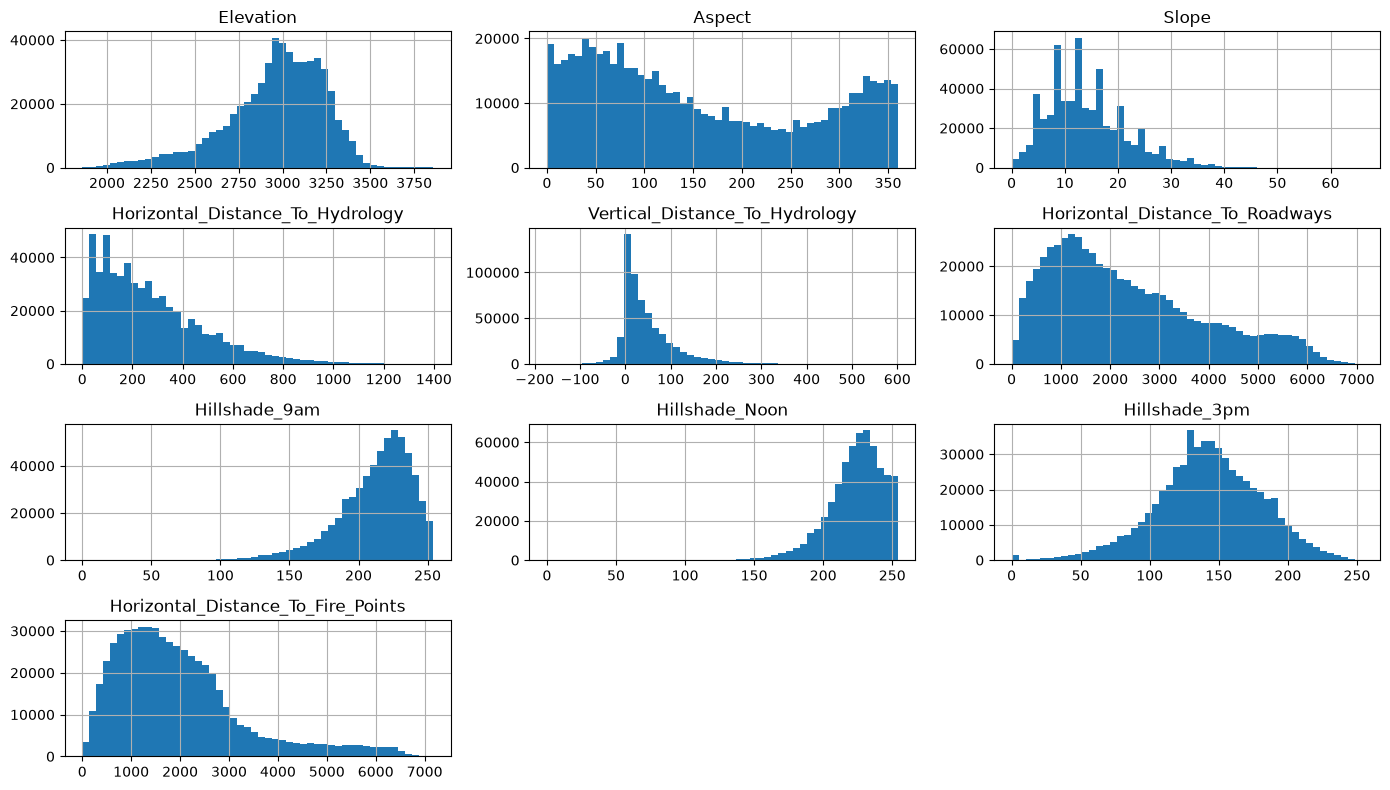

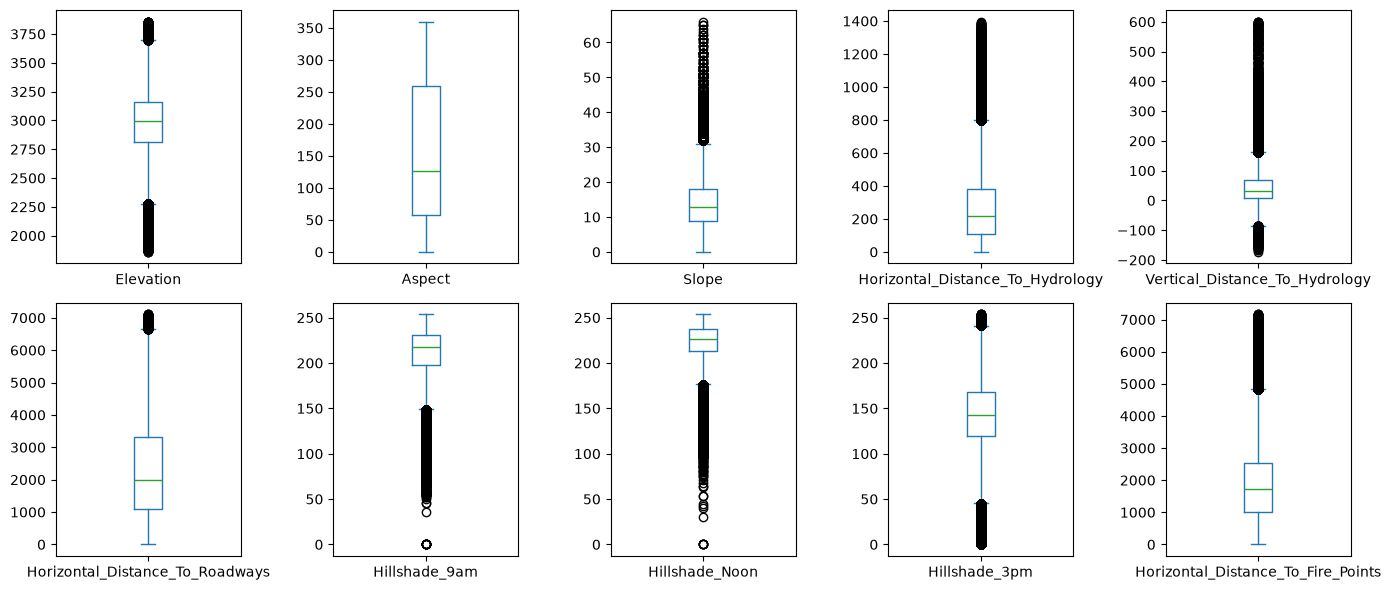

In [103]:
def audit_distributions(df, cont_cols):
    d = df[cont_cols]
    q1, q3 = d.quantile(.25), d.quantile(.75)
    iqr = q3 - q1
    mask = (d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)
    z = ((d - d.mean()) / d.std()).abs()
    display(pd.DataFrame({
        "min": d.min(), "max": d.max(), "mean": d.mean().round(1), "std": d.std().round(1),
        "skew": d.skew().round(2),
        "% IQR": (mask.mean() * 100).round(2),
        "% |z|>3": ((z > 3).mean() * 100).round(2),
    }))
    print(f"Lignes avec au moins un outlier (IQR) : {mask.any(axis=1).mean() * 100:.1f} %")

    d.hist(bins=50, figsize=(14, 8)); plt.tight_layout(); plt.show()
    d.plot(kind="box", subplots=True, layout=(2, 5), figsize=(14, 6), sharex=False)
    plt.tight_layout(); plt.show()

audit_distributions(data, cont_cols)

Commentaires :

*Distributions* : aucune variable continue n'est gaussienne et les échelles diffèrent beaucoup (de 0-360 pour `Aspect` à 0-7 173 pour les distances), d'où un scaling nécessaire pour les modèles sensibles aux distances.
- **Asymétrie à gauche :** `Elevation`, `Hillshade_9am`, `Hillshade_Noon`.
- **Asymétrie à droite :** `Slope` et les quatre distances. `Vertical_Distance_To_Hydrology` est la plus marquée (skew 1,79), avec un pic à 0 et des valeurs négatives normales (parcelle sous le point d'eau).
- **Quasi symétrique :** `Hillshade_3pm` (skew -0,28).
- **Circulaire :** `Aspect` (0° = 360°), à transformer en sin/cos.

*Interprétation des outliers* : 18,6 % des lignes ont au moins un outlier selon l'IQR (de 0,1 % à 5,4 % par variable). `Aspect` est exclu de cette lecture : son IQR est du même ordre que son étendue (0 à 360°), donc les bornes dépassent la plage possible et son 0 % n'a pas de sens pour un angle circulaire. L'IQR surestime les outliers sur des distributions asymétriques, ce qui explique en partie ce chiffre. Les valeurs extrêmes correspondent à des parcelles réelles (altitudes extrêmes, zones isolées, fortes pentes) et non à des erreurs de saisie, à l'exception des rares `Hillshade` à 0 à midi et à 9 h.

*Stratégies possibles* :
- **Outliers** : supprimer les lignes, plafonner (winsorisation), transformer (log, Yeo-Johnson) ou conserver.
- **Scaling** : `StandardScaler`, `MinMaxScaler` ou `RobustScaler` (médiane et IQR, résiste aux outliers).

*Stratégie choisie* :
- **Outliers** : conservation de toutes les lignes. Supprimer 18,6 % du jeu serait coûteux et retirerait des cas réels ; les arbres et forêts y sont insensibles.
- **Scaling** : `StandardScaler` sur les colonnes continues excepté `Aspect`, dans le pipeline, pour les modèles sensibles aux échelles. Aucun scaling pour les arbres. Les 44 binaires restent en `passthrough`.
- **Transformations** : `Aspect` remplacé par `sin` et `cos` (angle circulaire), utile aux modèles linéaires et KNN, sans effet négatif sur les arbres et forêts. Aucune autre transformation pour l'instant (asymétrie modérée, |skew| ≤ 1,8). On pourra appliquer Yeo-Johnson sur `Vertical_Distance_To_Hydrology` (un log est impossible à cause de ses valeurs négatives) si les modèles linéaires le justifient.

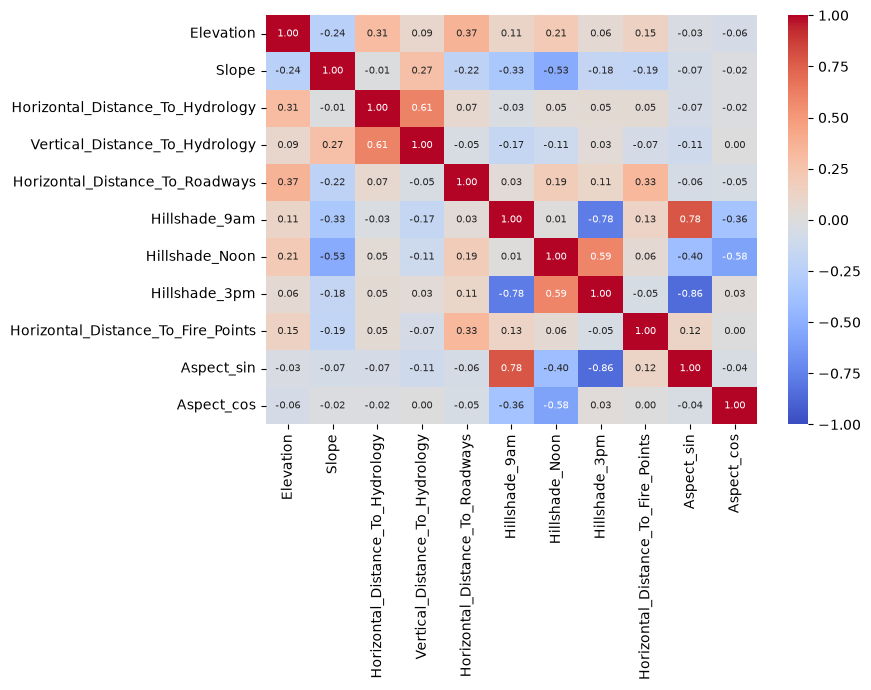

Elevation                             0.45
Wilderness_Area_3                     0.15
Horizontal_Distance_To_Roadways       0.09
Horizontal_Distance_To_Fire_Points    0.07
Wilderness_Area_0                     0.07
Soil_Type_9                           0.06
Slope                                 0.04
Soil_Type_37                          0.03
Soil_Type_28                          0.03
Soil_Type_38                          0.03
Soil_Type_3                           0.03
Horizontal_Distance_To_Hydrology      0.03
Hillshade_9am                         0.03
Soil_Type_21                          0.02
Soil_Type_11                          0.02
Soil_Type_1                           0.02
Hillshade_3pm                         0.02
Soil_Type_5                           0.02
Soil_Type_22                          0.02
Hillshade_Noon                        0.02
dtype: float64

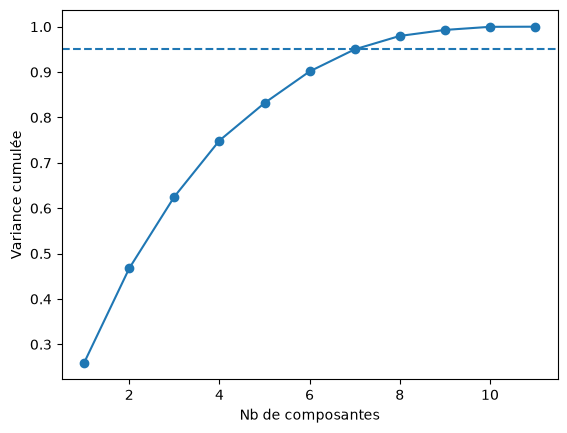

Composantes pour 95 % : 7


Cover_Type
1     3.3
2     4.2
3    16.1
4     8.7
5     6.0
6     8.1
7     9.8
Name: % anomalies, dtype: float64

In [115]:
from sklearn.preprocessing import StandardScaler

rad = np.deg2rad(data["Aspect"])
data_eda = data.drop(columns="Aspect").assign(Aspect_sin=np.sin(rad), Aspect_cos=np.cos(rad))
cont_eda = [c for c in cont_cols if c != "Aspect"] + ["Aspect_sin", "Aspect_cos"]
sample = data_eda.groupby(target, group_keys=False).sample(frac=0.1, random_state=RANDOM_STATE)
y_s = target.loc[sample.index]

# 1) Corrélations entre continues
plt.figure(figsize=(9, 7))
sns.heatmap(data_eda[cont_eda].corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.tight_layout(); plt.show()

# 2) Sélection : information mutuelle avec la cible (top 20)
mi = pd.Series(
    mutual_info_classif(sample, y_s, random_state=RANDOM_STATE,
                        discrete_features=[c not in cont_eda for c in sample.columns]),
    index=sample.columns).sort_values(ascending=False)
display(mi.head(20).round(2))

# 3) Réduction de dimension : variance cumulée de la PCA
Z = StandardScaler().fit_transform(data_eda[cont_eda])
cum = PCA().fit(Z).explained_variance_ratio_.cumsum()
plt.plot(range(1, len(cum) + 1), cum, marker="o"); plt.axhline(0.95, ls="--")
plt.xlabel("Nb de composantes"); plt.ylabel("Variance cumulée"); plt.show()
print("Composantes pour 95 % :", int(np.argmax(cum >= 0.95)) + 1)

# 4) Anomalies : % d'anomalies par classe (Isolation Forest, 5 %)
Zs = StandardScaler().fit_transform(sample[cont_eda])
anom = IsolationForest(contamination=0.05, random_state=RANDOM_STATE).fit_predict(Zs) == -1
display(pd.Series(anom, index=sample.index).groupby(y_s).mean().mul(100).round(1).rename("% anomalies"))

Commentaire :

*Corrélation et sélection* : les trois `Hillshade` sont fortement corrélées entre elles et avec `Aspect_sin`, `Aspect_cos` et `Slope` (|r| jusqu'à 0,86), donc redondantes. `Elevation` est de loin la plus liée à la cible (information mutuelle 0,45). Plusieurs `Soil_Type` ont une information mutuelle proche de 0 avec la cible, prises individuellement.

*Réduction de dimension* : 7 composantes sur 11 conservent 95 % de la variance des continues.

*Anomalies* : Isolation Forest (contamination fixée à 5 %, échantillon stratifié de 10 %, soit 58 101 lignes) signale surtout des parcelles des classes rares : 16 % de la classe 3, environ 9 à 10 % des classes 4 et 7 et 8 % de la 6, contre 3 à 4 % pour les classes 1 et 2. Cela suggère que ces parcelles sont atypiques parce que leur classe l'est (cf partie 1.3 Target analysis) : les supprimer retirerait des exemples des classes à prédire.

*Stratégies possibles* : retirer les variables redondantes, projeter les continues par PCA, supprimer ou conserver les anomalies.

*Décision* : deux entrées de pipeline : A (toutes les variables), B (sans les `Hillshade`). Anomalies conservées.

#### 1.3 Target analysis

,effectif,part (%)
Cover_Type,,
1,211840,36.46
2,283301,48.76
3,35754,6.15
4,2747,0.47
5,9493,1.63
6,17367,2.99
7,20510,3.53


Classes : 7 | ratio max/min : 103
Baseline (classe majoritaire) : 48.8 % d'accuracy


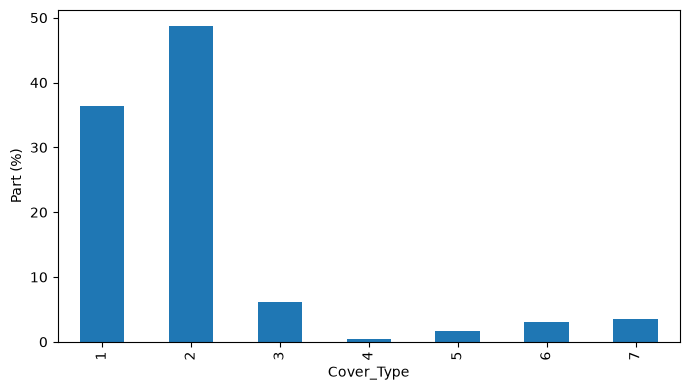

In [104]:
def audit_target(y):
    vc = y.value_counts().sort_index()
    display(pd.DataFrame({"effectif": vc, "part (%)": (vc / len(y) * 100).round(2)}))
    print(f"Classes : {y.nunique()} | ratio max/min : {vc.max() / vc.min():.0f}")
    print(f"Baseline (classe majoritaire) : {vc.max() / len(y) * 100:.1f} % d'accuracy")
    (vc / len(y) * 100).plot(kind="bar", figsize=(7, 4), xlabel=y.name, ylabel="Part (%)")
    plt.tight_layout(); plt.show()

audit_target(target)

Commentaire :

*Distribution de la cible* : 7 classes, très déséquilibrées. Les classes 1 et 2 représentent 85 % des parcelles (36,5 % et 48,8 %), alors que la classe 4 n'en compte que 0,47 % (2 747 parcelles). Le rapport entre la plus grande et la plus petite classe supérieur à 100.

*Interprétation* : un modèle qui prédit toujours la classe 2 obtient 48,8 % d'accuracy sans rien apprendre. L'accuracy seule est donc trompeuse ; les classes rares (4, 5, 6) risquent d'être mal prédites car elles pèsent peu dans l'erreur globale.

*Stratégies possibles* :
- Rééquilibrage : sous-échantillonnage des classes majoritaires, sur-échantillonnage des rares (par duplication ou SMOTE), ou pondération des classes (`class_weight="balanced"`).
- Évaluation : F1 macro, rappel par classe, matrice de confusion.
- Split : stratifié sur la cible.

*Stratégie choisie* :
- Split train/test et validation croisée stratifiés, pour garder les proportions dans chaque jeu.
- Métrique principale : F1 macro, avec l'accuracy en complément et la matrice de confusion pour le détail par classe.
- Pas de rééquilibrage des données au départ : `class_weight="balanced"` sera testé en variante dans les modèles qui le supportent. Sur-échantillonner avant le split fausserait l'évaluation, et à ce volume (581 012 lignes) les classes rares ont déjà un effectif exploitable (2 747 pour la plus petite).

#### 1.4 Clustering non supervisé

##### 1.4.1 Sans les features binaires

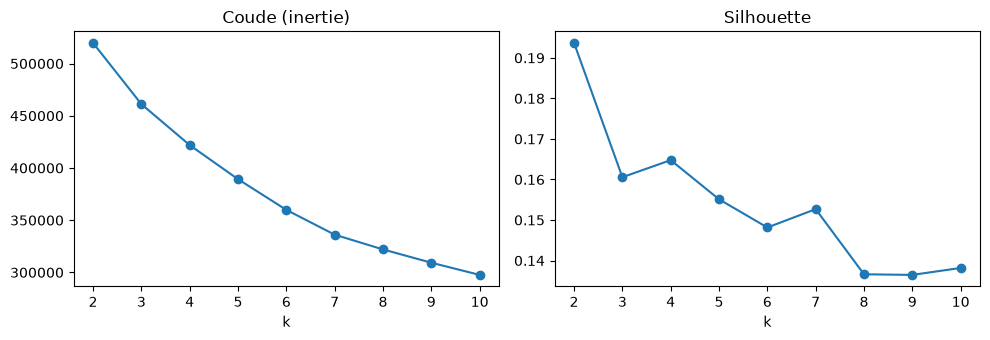

ARI : 0.018 | NMI : 0.049


Cover_Type,1,2,3,4,5,6,7
cluster (KMeans),,,,,,,
0,43.0,43.0,1.0,0.0,1.0,0.0,11.0
1,34.0,52.0,6.0,1.0,2.0,2.0,3.0
2,34.0,63.0,0.0,0.0,0.0,0.0,3.0
3,21.0,38.0,24.0,1.0,1.0,14.0,1.0
4,45.0,46.0,2.0,0.0,1.0,3.0,2.0
5,40.0,51.0,3.0,0.0,1.0,1.0,3.0
6,28.0,42.0,14.0,2.0,4.0,7.0,3.0


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Réutilise Zs (sous échantillon calculé plus haut), sample, y_s de l'étape 4
idx = np.random.RandomState(RANDOM_STATE).choice(len(Zs), 10000, replace=False)   # sous-échantillon pour la silhouette
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=5, random_state=RANDOM_STATE).fit(Zs)
    res.append((k, km.inertia_, silhouette_score(Zs[idx], km.labels_[idx])))
res = pd.DataFrame(res, columns=["k", "inertie", "silhouette"]).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
res["inertie"].plot(marker="o", ax=ax[0], title="Coude (inertie)")
res["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette")
plt.tight_layout(); plt.show()

# Lien avec la cible : k = 7 (nombre de classes)
km = KMeans(7, n_init=10, random_state=RANDOM_STATE).fit(Zs)
lab = pd.Series(km.labels_, index=sample.index, name="cluster (KMeans)")   # index = celui de y_s (sinon crosstab faux)
print("ARI :", round(adjusted_rand_score(y_s, lab), 3), "| NMI :", round(normalized_mutual_info_score(y_s, lab), 3))
display(pd.crosstab(lab, y_s, normalize="index").mul(100).round(0))   # composition de chaque cluster

##### 1.4.2 Avec les features binaires

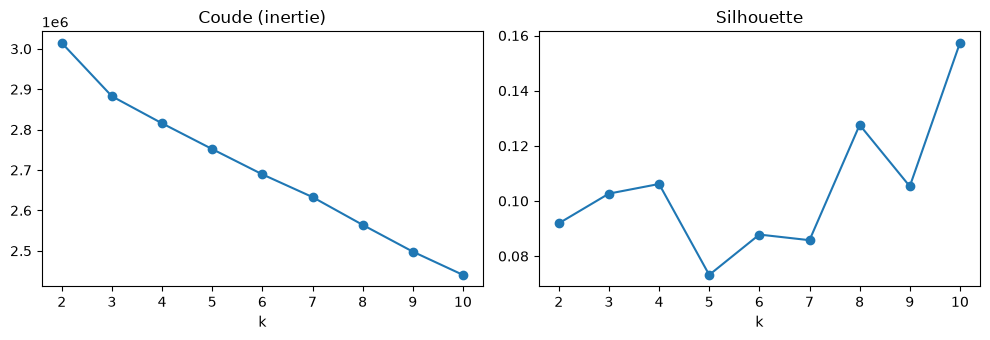

ARI : 0.054 | NMI : 0.159


Cover_Type,1,2,3,4,5,6,7
cluster,,,,,,,
0,45.0,51.0,0.0,0.0,1.0,0.0,3.0
1,38.0,45.0,4.0,0.0,2.0,3.0,8.0
2,26.0,58.0,9.0,0.0,3.0,2.0,1.0
3,0.0,9.0,57.0,7.0,0.0,27.0,0.0
4,17.0,78.0,0.0,0.0,4.0,0.0,0.0
5,54.0,44.0,0.0,0.0,0.0,1.0,1.0
6,76.0,23.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

# Toutes les variables (continues + binaires), standardisées
Zall = StandardScaler().fit_transform(sample)
idx = np.random.RandomState(RANDOM_STATE).choice(len(Zall), 10000, replace=False)   # sous-échantillon pour la silhouette
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=5, random_state=RANDOM_STATE).fit(Zall)
    res.append((k, km.inertia_, silhouette_score(Zall[idx], km.labels_[idx])))
res = pd.DataFrame(res, columns=["k", "inertie", "silhouette"]).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
res["inertie"].plot(marker="o", ax=ax[0], title="Coude (inertie)")
res["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette")
plt.tight_layout(); plt.show()

# Lien avec la cible : k = 7 (nombre de classes)
km = KMeans(7, n_init=10, random_state=RANDOM_STATE).fit(Zall)
lab = pd.Series(km.labels_, index=sample.index, name="cluster")   # index = celui de y_s (sinon crosstab faux)
print("ARI :", round(adjusted_rand_score(y_s, lab), 3), "| NMI :", round(normalized_mutual_info_score(y_s, lab), 3))
display(pd.crosstab(lab, y_s, normalize="index").mul(100).round(0))   # composition de chaque cluster

Commentaire :

*Clustering* : K-Means sur les 11 continues standardisées (échantillon stratifié de 10 %). Ni le coude ni la silhouette (0,19 pour k = 2, environ 0,15 ensuite) ne montrent de structure en groupes bien séparés. Avec k = 7, les clusters ne retrouvent pas les classes (ARI = 0,018 ; NMI = 0,049) : presque tous mélangent surtout les classes 1 et 2. En ajoutant les variables binaires, le lien avec la cible augmente un peu (ARI = 0,054 ; NMI = 0,159) mais reste faible

*Décision* : le clustering non supervisé, avec ou sans les variables binaires, ne sépare pas les classes (ARI très faible dans les deux cas), ce qui justifie un apprentissage supervisé. Pas de variable cluster ajoutée aux pipelines A et B.

#### 1.5 Interprétations, hypothèses et conclusions

*Ce que montre l'analyse* : le jeu de données (581 012 parcelles, 10 variables continues et 44 binaires déjà encodées) est propre : ni valeurs manquantes, ni doublons, ni colonnes constantes. Les continues sont asymétriques et d'échelles très différentes, avec 18,6 % de lignes contenant au moins un outlier selon l'IQR, qui correspondent à des parcelles réelles. La cible est déséquilibrée : les classes 1 et 2 représentent 85 % des parcelles, la classe 4 seulement 0,47 %, et prédire toujours la classe 2 donne 48,8 % d'accuracy. `Elevation` est de loin la variable la plus liée à la cible (information mutuelle 0,45). Les `Hillshade` sont redondantes avec `Aspect` et `Slope`. Les anomalies se concentrent sur les classes rares. Le clustering K-Means ne retrouve pas les classes : ARI = 0,018 sur les continues, 0,054 avec toutes les variables.

*Hypothèses (à tester dans la partie modélisation)* :
- Les classes se séparent surtout grâce à `Elevation`, aux `Wilderness_Area` et aux distances aux routes et aux départs de feu, qui ont les informations mutuelles les plus élevées avec la cible (0,45 pour `Elevation`, 0,15 pour `Wilderness_Area4`, 0,09 pour `Horizontal_Distance_To_Roadways`).
- Les classes 1 et 2, qui dominent, se chevauchent beaucoup : les confusions entre elles seront probablement les plus fréquentes.
- Les classes rares (3 à 7) seront plus difficiles à prédire : peu d'exemples et parcelles plus atypiques.
- Retirer les `Hillshade` (pipeline B) devrait peu dégrader les modèles, car elles sont redondantes.

*Conclusions pour la suite* :
- Toutes les lignes sont conservées (outliers plausibles, anomalies concentrées sur les classes rares). `Aspect` est remplacé par `Aspect_sin` et `Aspect_cos`, et `StandardScaler` s'applique aux continues sauf pour les arbres. Les binaires restent inchangées.
- Découpage et validation croisée stratifiés, F1 macro comme métrique principale (accuracy et matrice de confusion en complément), `class_weight="balanced"` testé en variante.
- Deux entrées comparées : A (toutes les variables) et B (sans les `Hillshade`).
- Le clustering non supervisé ne suffit pas à séparer les classes : un apprentissage supervisé est nécessaire.